# Demo: Orquestador multi-agente de vulnerabilidades

Este notebook muestra el **flujo de delegación** del sistema:

1. El grafo y su topología jerárquica.
2. Una consulta real: Supervisor → Investigador → Supervisor → Analista → Supervisor (rúbrica) → Síntesis.
3. La trazabilidad: qué agente aportó qué (`contributions`).
4. El **bucle de refinamiento**: el supervisor detecta un reporte que no cumple la rúbrica y se lo devuelve al analista.
5. Los **frenos** contra el supervisor infinito.
6. (Opcional) Las trazas completas en **Arize Phoenix**.

In [1]:
# Observabilidad (opcional): si Phoenix está corriendo (`uv run phoenix serve`),
# todas las llamadas quedan trazadas en http://localhost:6006. Debe ir ANTES de importar el grafo.
from tracing import setup_tracing
setup_tracing(project_name="vuln-orchestrator-notebook")

from IPython.display import Image, Markdown, display
import pandas as pd

from graph import graph
from state import initial_state, MAX_STEPS, MAX_RUNS_PER_AGENT

print(f"MAX_STEPS={MAX_STEPS} | MAX_RUNS_PER_AGENT={MAX_RUNS_PER_AGENT}")

🔭 Tracing activo -> http://localhost:6006


MAX_STEPS=8 | MAX_RUNS_PER_AGENT=3


## 1. El grafo
Las líneas punteadas son **aristas condicionales**: el supervisor elige el destino. Los especialistas siempre vuelven al supervisor.

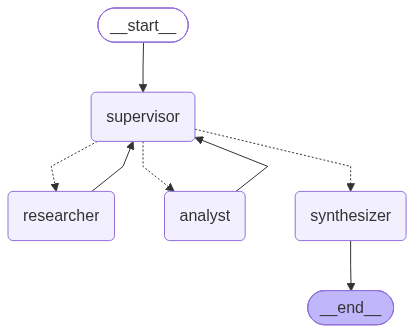

In [2]:
display(Image(graph.get_graph().draw_mermaid_png()))

## 2. Consulta real con 4 ecosistemas (Maven, npm, PyPI, Packagist)
`stream_mode="updates"` emite un evento por cada nodo ejecutado: así vemos la delegación en vivo.

In [3]:
query = ("Tengo estas dependencias: lodash 4.17.15 (npm), django 3.2.0 (PyPI), "
         "log4j-core 2.14.1 (Maven) y guzzlehttp/guzzle 7.4.0 (Packagist). "
         "¿Qué vulnerabilidades tienen y cuál debería arreglar primero?")

final = {}
for event in graph.stream(initial_state(query), config={"recursion_limit": 30}, stream_mode="updates"):
    for node, update in event.items():
        final.update({k: v for k, v in update.items() if k != "contributions"})
        final.setdefault("contributions", []).extend(update.get("contributions", []))
        if node == "supervisor":
            print(f"🧭 {update['messages'][0].content}\n")
        else:
            print(f"✅ {node} terminó\n")

🧭 [paso 1] -> researcher. No se han realizado consultas aún, por lo que el researcher debe investigar las vulnerabilidades de las dependencias solicitadas.
Instrucción: Consulta las vulnerabilidades de lodash 4.17.15, django 3.2.0, log4j-core 2.14.1 y guzzlehttp/guzzle 7.4.0 en OSV.dev y la web.



✅ researcher terminó



🧭 [paso 2] -> analyst. El researcher ha completado su tarea y ha proporcionado información sobre las vulnerabilidades; ahora es el momento de que el analyst realice su análisis y elabore un plan de acción.
Instrucción: Analiza las vulnerabilidades encontradas y elabora un plan de remediación ordenado y concreto, priorizando las vulnerabilidades críticas y altas.



✅ analyst terminó



🧭 [paso 3] -> analyst. El análisis tiene fallos en la presentación de las versiones recomendadas, lo que afecta la claridad del plan de acción. | Fallos de rúbrica: A2: la fila de log4j-core no indica la versión recomendada 2.25.4; A2: la fila de django no indica la versión recomendada 5.2.16; A2: la fila de guzzle no indica la versión recomendada 7.15.2
Instrucción: Corregí tu reporte: A2: la fila de log4j-core no indica la versión recomendada 2.25.4; A2: la fila de django no indica la versión recomendada 5.2.16; A2: la fila de guzzle no indica la versión recomendada 7.15.2. Mantené el resto igual.



✅ analyst terminó



🧭 [paso 4] -> FINISH. Todos los criterios de la rúbrica están cumplidos y no hay fallos que corregir.



✅ synthesizer terminó



### Respuesta final

In [4]:
display(Markdown(final['final_answer']))

# Reporte de vulnerabilidades

**Resumen ejecutivo**: La vulnerabilidad más crítica se encuentra en **log4j-core** (CVE-2021-44228), que permite la inyección de código remoto y tiene un CVSS de 10.0. Es urgente actualizar este paquete para mitigar el riesgo inmediato. Además, **django** presenta una vulnerabilidad de inyección SQL (CVE-2022-28346) con un CVSS de 9.8, lo que también requiere atención prioritaria.

## Prioridades
| Prioridad | Paquete                          | Versión actual | CVSS máx | Críticas/Altas | Actualizar a |
|-----------|----------------------------------|----------------|----------|----------------|---------------|
| 1         | log4j-core                      | 2.14.1         | 10.0     | 2/1            | 2.25.4       |
| 2         | django                           | 3.2.0          | 9.8      | 1/6            | 5.2.16       |
| 3         | lodash                           | 4.17.15        | 8.1      | 0/3            | 4.18.0       |
| 4         | guzzlehttp/guzzle               | 7.4.0          | 8.0      | 0/6            | 7.15.2       |

## Plan de acción
1. Actualizar **log4j-core** a la versión **2.25.4** para mitigar las vulnerabilidades críticas.
2. Actualizar **django** a la versión **5.2.16** para solucionar la vulnerabilidad crítica de inyección SQL.
3. Actualizar **lodash** a la versión **4.18.0** para remediar las vulnerabilidades de inyección de código.
4. Actualizar **guzzlehttp/guzzle** a la versión **7.15.2** para abordar las vulnerabilidades de seguridad.

## Contexto relevante
- CVE-2021-44228 (Log4j) es ampliamente conocido y ha sido objeto de explotación activa. Para más detalles, puedes consultar [este artículo](https://www.cisa.gov/uscert/ncas/alerts/2021/12/10/cisa-releases-emergency-directive-21-01-mitigate-log4j-vulnerability).

## Advertencias
- log4j-core: 4 scores aproximados (sin vector CVSS v3; estimados por etiqueta de severidad).
- django: análisis parcial, 15 de 66 vulnerabilidades analizadas.

## 3. Trazabilidad: quién aportó qué
El campo `contributions` usa el reducer `operator.add`: se acumula y nunca se pierde.

In [5]:
pd.set_option("display.max_colwidth", 90)
pd.DataFrame([
    {"paso": c["step"], "agente": c["agent"], "intento": c["attempt"],
     "instrucción": c["instruction"][-90:].replace("\n", " "), "aporte": c["content"][:90].replace("\n", " ")}
    for c in final["contributions"]
])

,paso,agente,intento,instrucción,aporte
0,1,supervisor,1,decidir próximo paso,"[paso 1] -> researcher. No se han realizado consultas aún, por lo que el researcher de..."
1,1,researcher,1,"sh 4.17.15, django 3.2.0, log4j-core 2.14.1 y guzzlehttp/guzzle 7.4.0 en OSV.dev y la ...",## Hallazgos por paquete - lodash@4.17.15 (npm): 5 vulns. Más relevantes: CVE-2021-233...
2,2,supervisor,1,decidir próximo paso,[paso 2] -> analyst. El researcher ha completado su tarea y ha proporcionado informaci...
3,2,analyst,1,rability). ## Limitaciones - Los datos de Django muestran solo 15 de 66 vulnerabilida...,## Ranking de riesgo | Prioridad | Paquete | Versión actual |...
4,3,supervisor,1,decidir próximo paso,[paso 3] -> analyst. El análisis tiene fallos en la presentación de las versiones reco...
5,3,analyst,2,"etiqueta de severidad). - django: análisis parcial, 15 de 66 vulnerabilidades analiza...",## Ranking de riesgo | Prioridad | Paquete | Versión actual |...
6,4,supervisor,1,decidir próximo paso,[paso 4] -> FINISH. Todos los criterios de la rúbrica están cumplidos y no hay fallos ...
7,4,synthesizer,1,síntesis final,# Reporte de vulnerabilidades **Resumen ejecutivo**: La vulnerabilidad más crítica se...


## 4. Bucle de refinamiento (validación del supervisor)

Simulamos que el analista entregó un reporte **sin las advertencias obligatorias** (criterio A3 de la rúbrica).
Arrancamos el grafo desde ese estado: el supervisor debería detectarlo y devolverle el trabajo **al analista** con una instrucción precisa.

In [6]:
state = initial_state(query)
state.update({k: final[k] for k in ("research_findings", "vulnerability_data")})
state["revisions"] = {"researcher": 1, "analyst": 1}
state["step_count"] = 2
state["analysis_report"] = (
    "## Ranking de riesgo\n| 1 | log4j-core | 10.0 |\n| 2 | django | 9.8 |\n| 3 | lodash | 8.1 |\n| 4 | guzzle | 8.0 |\n"
    "## Plan de acción\n1. Actualizar todo.\n## Datos faltantes / advertencias\n- ninguno"
)

for event in graph.stream(state, config={"recursion_limit": 30}, stream_mode="updates"):
    for node, update in event.items():
        if node == "supervisor":
            print(f"🧭 {update['messages'][0].content}\n")
        elif node == "analyst":
            rep = update["analysis_report"]
            print(f"📊 analyst (ejecución #{update['revisions']['analyst']}) — advertencias corregidas:")
            print(rep[rep.lower().find("datos faltantes"):], "\n")
        else:
            print(f"✅ {node} terminó\n")

🧭 [paso 3] -> analyst. El plan de acción no está ordenado según el ranking de riesgo, lo que impide una remediación efectiva. | Fallos de rúbrica: A4: el plan no está ordenado.; A3: no advierte que django se analizó parcialmente (15 de 66); A3: no advierte que log4j-core tiene 4 scores aproximados (sin CVSS v3); A2: la fila de log4j-core no indica la versión recomendada 2.25.4; A2: la fila de django no indica la versión recomendada 5.2.16; A2: la fila de lodash no indica la versión recomendada 4.18.0; A2: la fila de guzzle no indica la versión recomendada 7.15.2
Instrucción: Corregí tu reporte: A3: no advierte que django se analizó parcialmente (15 de 66); A3: no advierte que log4j-core tiene 4 scores aproximados (sin CVSS v3); A2: la fila de log4j-core no indica la versión recomendada 2.25.4; A2: la fila de django no indica la versión recomendada 5.2.16; A2: la fila de lodash no indica la versión recomendada 4.18.0; A2: la fila de guzzle no indica la versión recomendada 7.15.2. Manten

📊 analyst (ejecución #2) — advertencias corregidas:
Datos faltantes / advertencias
- log4j-core: 4 scores aproximados (sin vector CVSS v3; estimados por etiqueta de severidad).
- django: análisis parcial, 15 de 66 vulnerabilidades analizadas. 



🧭 [paso 4] -> analyst. El plan de acción debe reflejar el orden de prioridad basado en el riesgo, lo cual no se cumple en el reporte actual. | Fallos de rúbrica: A4: el plan no está ordenado por prioridad de riesgo.
Instrucción: Reordena el plan de acción según la prioridad de riesgo, comenzando por log4j-core, seguido de django, lodash y guzzlehttp/guzzle.



📊 analyst (ejecución #3) — advertencias corregidas:
Datos faltantes / advertencias
- log4j-core: 4 scores aproximados (sin vector CVSS v3; estimados por etiqueta de severidad).
- django: análisis parcial, 15 de 66 vulnerabilidades analizadas. 



🧭 [paso 5] -> FINISH. El plan de acción debe reflejar el orden de prioridad basado en el riesgo, lo cual no se cumple en el reporte actual. | Fallos de rúbrica: A4: el plan no está ordenado por prioridad de riesgo. | Guardrails: G3: analyst alcanzó 3 ejecuciones -> FINISH



✅ synthesizer terminó



## 5. Frenos contra el supervisor infinito (sin LLM)
Aunque el LLM quiera seguir refinando, los guardrails en código lo cortan:

In [7]:
from agents.supervisor import SupervisorDecision, apply_guardrails

terco = SupervisorDecision(research_issues=[], analysis_issues=["no me gusta"], next_agent="analyst",
                           instruction="otra vez", reasoning="quiero seguir")

s = initial_state(query) | {"vulnerability_data": final["vulnerability_data"], "analysis_report": final["analysis_report"]}
print("Analista ya corrió 3 veces ->", apply_guardrails(terco, s | {"revisions": {"researcher": 1, "analyst": 3}})[::2])
print("Paso 8 de 8               ->", apply_guardrails(terco, s | {"step_count": MAX_STEPS - 1})[::2])

Analista ya corrió 3 veces -> ('FINISH', ['G3: analyst alcanzó 3 ejecuciones -> FINISH'])
Paso 8 de 8               -> ('FINISH', ['G4: se alcanzó MAX_STEPS=8 -> FINISH'])


## 6. Trazas en Arize Phoenix
Si Phoenix está corriendo, abrí http://localhost:6006 → proyecto `vuln-orchestrator-notebook`. Cada corrida del grafo es una traza con los spans de supervisor, agentes, llamadas al LLM (prompt, respuesta, tokens) y tools.

In [8]:
from tracing import flush_tracing
flush_tracing()  # envía los spans pendientes antes de ir a mirar Phoenix